In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("My Task 1 project has started successfully!")

My Task 1 project has started successfully!


In [ ]:

# Load the required Iris dataset
import pandas as pd

df = pd.read_csv("/content/iris.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

print("\nFirst 5 rows:")
display(df.head())

print("\nFlower species:")
print(df["species"].unique())


Dataset loaded successfully!
Dataset shape: (150, 5)

First 5 rows:


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa



Flower species:
['setosa' 'versicolor' 'virginica']


In [ ]:

# Check dataset information
print("Dataset information:")
df.info()

print("\nStatistical summary:")
display(df.describe())

print("\nMissing values:")
print(df.isnull().sum())

print("\nNumber of flowers in each species:")
print(df["species"].value_counts())


Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB

Statistical summary:


,sepal_length,sepal_width,petal_length,petal_width
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000



Missing values:
sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64

Number of flowers in each species:
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


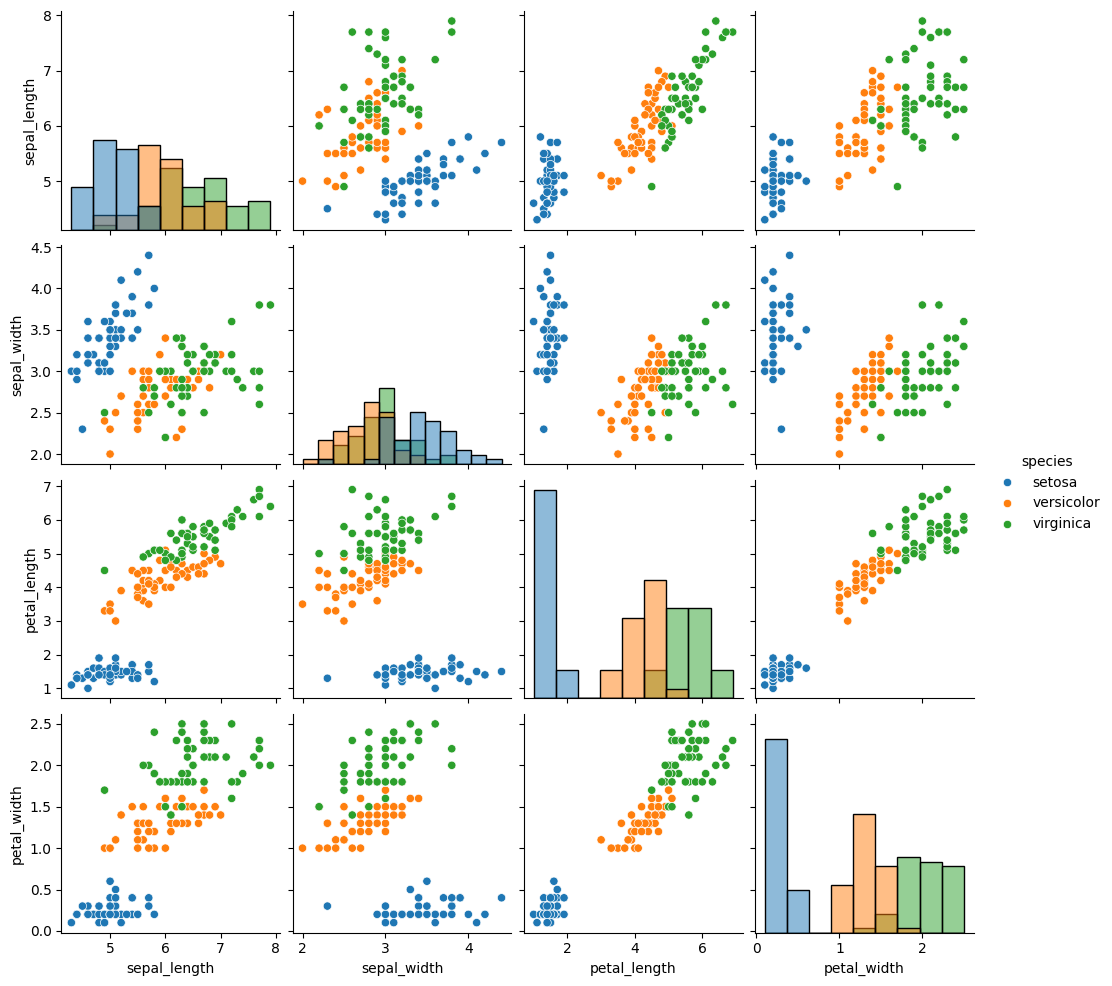

In [ ]:

# Create a pairplot to compare flower measurements
sns.pairplot(
    df,
    hue="species",
    diag_kind="hist"
)

plt.show()


In [ ]:

from sklearn.model_selection import train_test_split

# Separate input features and target
X = df.drop(columns=["species"])
y = df["species"]

# Split the dataset into 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Display the sizes
print("Total samples:", len(df))
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining feature shape:", X_train.shape)
print("Testing feature shape:", X_test.shape)


Total samples: 150
Training samples: 120
Testing samples: 30

Training feature shape: (120, 4)
Testing feature shape: (30, 4)


In [ ]:

from sklearn.preprocessing import StandardScaler

# Create the scaler
scaler = StandardScaler()

# Fit on training data and transform it
X_train_scaled = scaler.fit_transform(X_train)

# Transform testing data using the same scaler
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed successfully!")

print("Scaled training data shape:", X_train_scaled.shape)
print("Scaled testing data shape:", X_test_scaled.shape)


Feature scaling completed successfully!
Scaled training data shape: (120, 4)
Scaled testing data shape: (30, 4)


In [ ]:

from sklearn.linear_model import LogisticRegression

# Create the Logistic Regression model
log_model = LogisticRegression(max_iter=1000)

# Train the model using scaled training data
log_model.fit(X_train_scaled, y_train)

print("Logistic Regression model trained successfully!")


Logistic Regression model trained successfully!


In [ ]:

from sklearn.tree import DecisionTreeClassifier

# Create the Decision Tree model
tree_model = DecisionTreeClassifier(random_state=42)

# Train using the original training features
tree_model.fit(X_train, y_train)

print("Decision Tree model trained successfully!")


Decision Tree model trained successfully!


In [ ]:

# Predict using both models
log_pred = log_model.predict(X_test_scaled)
tree_pred = tree_model.predict(X_test)

print("Logistic Regression predictions:")
print(log_pred)

print("\nDecision Tree predictions:")
print(tree_pred)

print("\nActual flower species:")
print(y_test.to_numpy())


Logistic Regression predictions:
['setosa' 'virginica' 'versicolor' 'versicolor' 'setosa' 'versicolor'
 'setosa' 'setosa' 'virginica' 'versicolor' 'virginica' 'virginica'
 'virginica' 'versicolor' 'setosa' 'setosa' 'setosa' 'versicolor'
 'versicolor' 'virginica' 'setosa' 'virginica' 'versicolor' 'versicolor'
 'virginica' 'virginica' 'versicolor' 'setosa' 'virginica' 'setosa']

Decision Tree predictions:
['setosa' 'virginica' 'versicolor' 'versicolor' 'setosa' 'versicolor'
 'setosa' 'setosa' 'virginica' 'versicolor' 'virginica' 'virginica'
 'virginica' 'versicolor' 'setosa' 'setosa' 'setosa' 'versicolor'
 'versicolor' 'virginica' 'setosa' 'virginica' 'versicolor' 'versicolor'
 'virginica' 'virginica' 'versicolor' 'setosa' 'virginica' 'setosa']

Actual flower species:
['setosa' 'virginica' 'versicolor' 'versicolor' 'setosa' 'versicolor'
 'setosa' 'setosa' 'virginica' 'versicolor' 'virginica' 'virginica'
 'virginica' 'versicolor' 'setosa' 'setosa' 'setosa' 'versicolor'
 'versicolor' 'virg

In [ ]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
import pandas as pd

def evaluate_model(name, actual, predicted):
    return {
        "Model": name,
        "Accuracy": accuracy_score(actual, predicted),
        "Precision": precision_score(
            actual, predicted, average="weighted"
        ),
        "Recall": recall_score(
            actual, predicted, average="weighted"
        ),
        "F1-Score": f1_score(
            actual, predicted, average="weighted"
        )
    }

results = pd.DataFrame([
    evaluate_model("Logistic Regression", y_test, log_pred),
    evaluate_model("Decision Tree", y_test, tree_pred)
])

display(results.round(4))


,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.9333,0.9333,0.9333,0.9333
1,Decision Tree,0.9333,0.9333,0.9333,0.9333


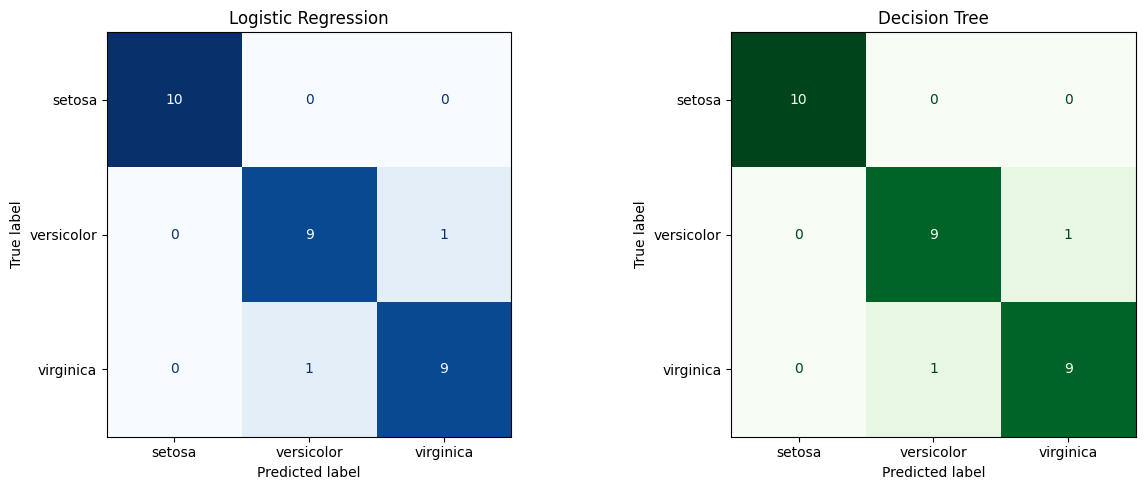

In [ ]:

from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Create two confusion matrices
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Logistic Regression confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    log_pred,
    labels=["setosa", "versicolor", "virginica"],
    cmap="Blues",
    ax=axes[0],
    colorbar=False
)

axes[0].set_title("Logistic Regression")

# Decision Tree confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    tree_pred,
    labels=["setosa", "versicolor", "virginica"],
    cmap="Greens",
    ax=axes[1],
    colorbar=False
)

axes[1].set_title("Decision Tree")

plt.tight_layout()
plt.show()
